epoch0, training_loss : 1.8946059538146196, test_loss: 1.6559761762619019, test_accuracy: 0.405982905982906
epoch1, training_loss : 1.4467390048301827, test_loss: 1.4387700319290162, test_accuracy: 0.3974358974358974
epoch2, training_loss : 1.2674849912271662, test_loss: 1.032694896062215, test_accuracy: 0.6666666666666666
epoch3, training_loss : 1.0342236636048656, test_loss: 0.9139994184176127, test_accuracy: 0.7051282051282052
epoch4, training_loss : 0.8571631322472782, test_loss: 0.8157760481039683, test_accuracy: 0.7136752136752137
epoch5, training_loss : 0.7377305404614594, test_loss: 0.8311133682727814, test_accuracy: 0.7094017094017094
epoch6, training_loss : 0.6458912011930498, test_loss: 0.7875895023345947, test_accuracy: 0.782051282051282
epoch7, training_loss : 0.706088349980823, test_loss: 0.7455375671386719, test_accuracy: 0.7777777777777778
epoch8, training_loss : 0.5578446797395157, test_loss: 0.9142998298009236, test_accuracy: 0.6923076923076923
epoch9, training_loss :

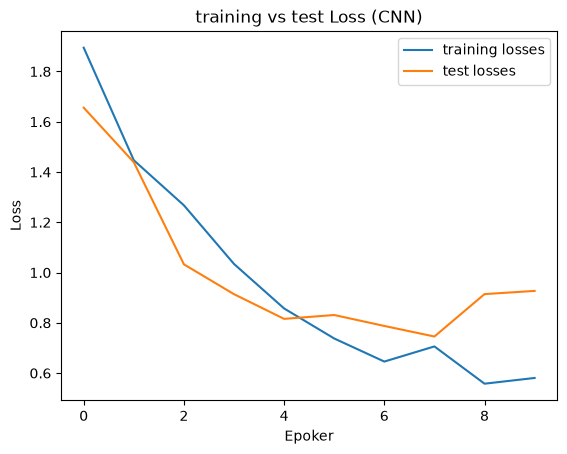

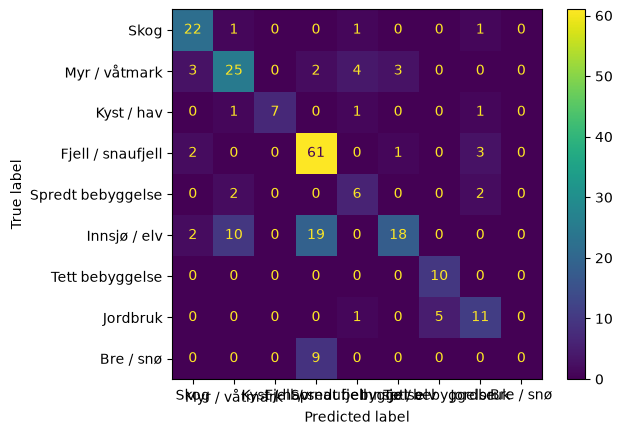

In [44]:
import pandas as pd, torch
from PIL import Image
import matplotlib.pyplot as plt
import torch
import cv2
import torchvision.transforms as transforms
from torch.utils.data import Dataset,TensorDataset
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import os 
from sklearn.model_selection import train_test_split 
import torch.nn as nn  
import matplotlib.pyplot as plt
import warnings
from collections import Counter



data = pd.read_csv("kartdatasett_1169/kartdatasett/etiketter.csv")



dictionary = {"Skog":"Skog","Myr / våtmark":"Myr_vatmark","Kyst / hav":"Kyst_hav","Fjell / snaufjell":"Fjell_snaufjell","Spredt bebyggelse":"Spredt_bebyggelse","Innsjø / elv":"Innsjo_elv","Tett bebyggelse":"Tett_bebyggelse","Jordbruk":"Jordbruk","Bre / snø":"Bre_sno"}
dictionary_nums = {"Skog":0,"Myr / våtmark":1,"Kyst / hav":2,"Fjell / snaufjell":3,"Spredt bebyggelse":4,"Innsjø / elv":5,"Tett bebyggelse":6,"Jordbruk":7,"Bre / snø":8}
dictionary_class_to_nums = {"Skog":0,"Myr_vatmark":1,"Kyst_hav":2,"Fjell_snaufjell":3,"Spredt_bebyggelse":4,"Innsjo_elv":5,"Tett_bebyggelse":6,"Jordbruk":7,"Bre_sno":8}
dictionary_nums_reverse = {0:"Skog",1:"Myr / våtmark",2:"Kyst / hav",3:"Fjell / snaufjell",4:"Spredt bebyggelse",5:"Innsjø / elv",6:"Tett bebyggelse",7:"Jordbruk",8:"Bre / snø"}
stier = []
klassenummere = []
for i,row in data.iterrows():
    current_biome = dictionary[row["klasse"]]
    current_img = row["fil"]
    img_link = os.path.join("kartdatasett_1169","kartdatasett",current_biome,current_img)
    if os.path.exists(img_link):
        stier.append(img_link)
        klassenummer = dictionary_nums[row["klasse"]]
        klassenummere.append(klassenummer)

data["stier"] = stier
data["klassenummere"] = klassenummere
cut_data = data[["Skog","Myr / våtmark","Kyst / hav","Fjell / snaufjell","Spredt bebyggelse","Innsjø / elv","Tett bebyggelse","Jordbruk","Bre / snø"]]
sum_each_row = cut_data.sum(axis=1)
row_truth = cut_data.idxmax(axis="columns")
row_other_truth = data["klasse"]
truth_rows = row_truth==row_other_truth
values = row_other_truth.value_counts()

#sample = data.groupby("klasse").sample(n=3,random_state=1)
#fig, axs = plt.subplots(9, 3)
#flat_axs = axs.flat
#fig.set_figwidth(25)
#fig.set_figheight(25)
##for (i,row),ax in zip(sample.iterrows(),flat_axs):
##    image = cv2.imread(row["stier"])
##
##    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
##    ax.set_axis_off()
##    ax.set_title(row["klasse"])
##    ax.imshow(image)
    

##plt.show()

#list_of_image_values = []
#for i, row in data.iterrows():
#    image = cv2.imread(row["stier"])
#    list_of_image_values.append(image.shape)
#
#print(Counter(list_of_image_values))



X_train, X_test, y_train, y_test = train_test_split(
    data["stier"], data["klassenummere"],stratify=data["klassenummere"], test_size=0.2, random_state=42)


def convert_to_stack(input_data):
    return_images = []
    for row in input_data:
        image = cv2.imread(row)
    
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        small_image = cv2.resize(image,(128,128),interpolation=cv2.INTER_AREA)
        return_images.append(small_image)
    train_images = np.stack(return_images)
    return train_images


X_train_images = convert_to_stack(X_train)
X_test_images = convert_to_stack(X_test)

X_train_tensor = torch.from_numpy(X_train_images)
X_test_tensor = torch.from_numpy(X_test_images)

X_train_tensor_permuted = torch.permute(X_train_tensor,(0, 3, 1, 2))
X_test_tensor_permuted = torch.permute(X_test_tensor,(0, 3, 1, 2))

X_train_tensor_float = X_train_tensor_permuted.float()
X_test_tensor_float = X_test_tensor_permuted.float()

X_train_normalized = X_train_tensor_float/255
X_test_normalized = X_test_tensor_float/255

numpy_y_train = y_train.to_numpy()
numpy_y_test = y_test.to_numpy()

tensor_y_train = torch.tensor(numpy_y_train,dtype=torch.long)
tensor_y_test = torch.tensor(numpy_y_test,dtype=torch.long)

#print(tensor_y_train)
#print(tensor_y_test)

dataset_training = TensorDataset(X_train_normalized, tensor_y_train)
dataset_test = TensorDataset(X_test_normalized, tensor_y_test)

train_loader = DataLoader(dataset_training,batch_size=16,shuffle=True)
test_loader = DataLoader(dataset_test,batch_size=16)

class CNN(torch.nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = torch.nn.Conv2d(in_channels=3,out_channels=16,kernel_size=3,stride=1,padding=1)
        self.conv2 = torch.nn.Conv2d(in_channels=16,out_channels=32,kernel_size=3,stride=1,padding=1)
        self.conv3 = torch.nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,stride=1,padding=1)
        self.relu = torch.nn.ReLU()
        self.pooling = torch.nn.MaxPool2d(2,2)
        self.flatten = torch.nn.Flatten()
        self.linear1 = torch.nn.Linear(16384,128)
        self.linear2 = torch.nn.Linear(128,9)

    def forward(self, x):
        x = self.pooling(self.relu(self.conv1(x)))
        x = self.pooling(self.relu(self.conv2(x)))
        x = self.pooling(self.relu(self.conv3(x)))
        x = self.flatten(x)
        x = self.relu(self.linear1(x))
        x = self.linear2(x)
        return x


model = CNN()

loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_epoch():
    model.train(True)
    running_loss = 0.
    for data in train_loader: 
        optimizer.zero_grad()
            
        dataloader_data, labels = data
            
        pred = model(dataloader_data)
            
        loss = loss_fn(pred,labels)

        loss.backward()

        optimizer.step()
        running_loss += loss.item()
    last_loss = running_loss / 59
        
    return last_loss


def evaluate():
    model.eval()
    full_loss = 0
    correct_answer_number = 0
    number_of_batches = 0
    with torch.no_grad():
        for data in test_loader:
            dataloader_data, labels = data
            
            pred = model(dataloader_data)

            prediction = torch.argmax(pred,dim=1)

            right_answers = prediction == labels

            correct_answer_number+= right_answers.sum().item()
            
            loss = loss_fn(pred,labels)

            full_loss += loss.item()

            number_of_batches += 1
    avg_loss = full_loss/number_of_batches

    accuracy = correct_answer_number/len(dataset_test)
    
    return accuracy, avg_loss


def show_confusion_matrix():
    predictions = []
    truth = []
    model.eval()
    with torch.no_grad():
        for data in test_loader:
            dataloader_data, labels = data
            
            pred = model(dataloader_data)
    
            prediction = torch.argmax(pred,dim=1)

            predictions.append(prediction)

            truth.append(labels)
    class_list = []
    for i in range(9):
        class_list.append(dictionary_nums_reverse[i])
    truth = torch.cat(truth)
    numpy_truth = truth.numpy()
    predictions = torch.cat(predictions)
    numpy_predictions = predictions.numpy()
    cm = confusion_matrix(numpy_truth, numpy_predictions,labels=range(9))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=class_list)
    disp.plot()
    plt.show()
    

training_losses = []
test_losses = []
test_accuracies = []
for epoch in range(10):
    training_loss = train_epoch()
    test_accuracy, test_loss = evaluate() 
    print(f"epoch{epoch}, training_loss : {training_loss}, test_loss: {test_loss}, test_accuracy: {test_accuracy}")
    training_losses.append(training_loss)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)


plt.plot(training_losses, label="training losses")
plt.plot(test_losses, label="test losses")
plt.title('training vs test Loss (CNN)')
plt.xlabel('Epoker')
plt.ylabel('Loss')
plt.legend()
plt.show()

show_confusion_matrix()


#print(tensor_y_train)
#print(dataset_training[0])
#print(dataset_training[0][0].shape)

#print(X_train_normalized.dtype)
#print(X_test_normalized.dtype)

#print(torch.max(X_train_normalized))
#print(torch.max(X_test_normalized))

#print(torch.min(X_train_normalized))
#print(torch.min(X_test_normalized))


#print(X_train_images.shape)
#print(X_test_images.shape)

#test_image = X_train_images[200]
#plt.imshow(test_image)
#plt.show()


#sum_of_differences = 0
#for row1, row2 in zip(X_test,y_test):
#    gate = os.path.dirname(row1)
#    klasse = os.path.basename(gate)
#    klasse_nr = dictionary_class_to_nums[klasse]
#    if klasse_nr != row2:
#        sum_of_differences += 1
#print(sum_of_differences)    

#print(X_train.index.equals(y_train.index))

#X_train_set = set(X_train)
#X_test_set = set(X_test)

#print(X_train_set.intersection(X_test_set))

#print(X_train.shape)
#print(X_test.shape)

#print(y_train.value_counts())
#print(y_test.value_counts())


